# Спецглавы баз данных

## Загрузка JSON в SQLite и анализ банковских данных

Источник — `bank_dataset.xlsx` из вебинаров 9 и 10. Из таблицы взяты 10 000 строк и пять полей — идентификатор клиента, город, возраст, кредитный балл и оценочный доход. Для проверки удаления дубликатов в конец `bank_clients.json` добавлено по одной точной копии строки из каждого города. [Исходная таблица](https://drive.google.com/uc?export=download&id=10OSA8ENKfan8mJrNgCmio8-q0qJkaPIy).

Для повторного запуска положите `bank_clients.json` рядом с ноутбуком и выполните все ячейки. Нужны Python, pandas и matplotlib. Ноутбук создаст файл базы `bank_clients.sqlite` и сохранит диаграмму в `city_statistics.png`.

### 1. Создаём базу SQLite и загружаем JSON

SQLite работает в процессе Python и хранит базу в локальном файле. Подключение открываем через `sqlite3.connect()`. Таблица `clients_raw` хранит все записи, включая дубликаты. При повторном запуске её содержимое обновляется в одной транзакции.

In [1]:
import json
import sqlite3
from contextlib import closing
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

json_path = Path("bank_clients.json")
db_path = Path("bank_clients.sqlite")

with json_path.open(encoding="utf-8") as file:
    records = json.load(file)

with closing(sqlite3.connect(db_path)) as connection, connection:
    connection.execute("BEGIN")
    connection.execute("""
        CREATE TABLE IF NOT EXISTS clients_raw (
            userid INTEGER NOT NULL,
            city TEXT NOT NULL,
            age INTEGER NOT NULL,
            score INTEGER NOT NULL,
            estimated_salary REAL NOT NULL
        )
    """)
    connection.execute("DELETE FROM clients_raw")
    connection.executemany("""
        INSERT INTO clients_raw (userid, city, age, score, estimated_salary)
        VALUES (:userid, :city, :age, :score, :estimated_salary)
    """, records)

print(f"Загружено в {db_path}: {len(records):,} строк".replace(",", " "))

Загружено в bank_clients.sqlite: 10 003 строк


### 2. Читаем данные из SQLite в pandas

Открываем новое подключение к файлу базы и выполняем SQL-запрос через `pd.read_sql_query()`.

In [2]:
read_uri = f"{db_path.resolve().as_uri()}?mode=ro"
with closing(sqlite3.connect(read_uri, uri=True)) as connection:
    raw = pd.read_sql_query("""
        SELECT userid, city, age, score, estimated_salary
        FROM clients_raw
        ORDER BY rowid
    """, connection)

print(f"Прочитано строк: {len(raw):,}".replace(",", " "))
raw.head()

Прочитано строк: 10 003


,userid,city,age,score,estimated_salary
0,15677338,Ярославль,42,619,101348.88
1,15690047,Рыбинск,41,608,112542.58
2,15662040,Ярославль,42,502,113931.57
3,15744090,Ярославль,39,699,93826.63
4,15780624,Рыбинск,43,850,79084.10


### 3. Удаляем дубликаты и выбросы

Сначала удаляем точные совпадения по всем пяти полям. Затем для возраста, кредитного балла и оценочного дохода рассчитываем первый и третий квартили по всем городам вместе. Межквартильный размах равен $IQR = Q_3 - Q_1$. Строку исключаем, если хотя бы один показатель выходит за пределы $[Q_1 - 1{,}5\,IQR; Q_3 + 1{,}5\,IQR]$. Общие границы позволяют применить одинаковое правило ко всем городам.

In [3]:
metric_labels = {
    "age": "Возраст",
    "score": "Кредитный балл",
    "estimated_salary": "Оценочный доход",
}
unique = raw.drop_duplicates()
measures = unique[list(metric_labels)]
q1 = measures.quantile(0.25)
q3 = measures.quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

outside_bounds = measures.lt(lower) | measures.gt(upper)
is_outlier = outside_bounds.any(axis=1)
clean = unique.loc[~is_outlier].copy()

print(f"Дубликатов удалено: {len(raw) - len(unique)}")
print(f"Строк с выбросами удалено: {is_outlier.sum()}")
print(f"Строк после очистки: {len(clean):,}".replace(",", " "))
bounds = pd.DataFrame({
    "Q1": q1,
    "Q3": q3,
    "Нижняя граница": lower,
    "Верхняя граница": upper,
    "Значений за границами": outside_bounds.sum(),
})
bounds.rename(index=metric_labels).round(2)

Дубликатов удалено: 3
Строк с выбросами удалено: 374
Строк после очистки: 9 626


,Q1,Q3,Нижняя граница,Верхняя граница,Значений за границами
Возраст,32.00,44.00,14.0,62.00,359
Кредитный балл,584.00,718.00,383.0,919.00,15
Оценочный доход,51002.11,149388.25,-96577.1,296967.45,0


### 4. Считаем статистики по городам

Для каждого показателя рассчитываем число наблюдений, среднее, медиану, выборочное стандартное отклонение, минимум и максимум. Оценочный доход приведён в единицах исходных данных.

In [4]:
stats = (
    clean.rename(columns={"city": "Город", **metric_labels})
    .melt(
        id_vars="Город",
        value_vars=list(metric_labels.values()),
        var_name="Показатель",
        value_name="Значение",
    )
    .groupby(["Показатель", "Город"])["Значение"]
    .agg(
        Число_наблюдений="count",
        Среднее="mean",
        Медиана="median",
        Стандартное_отклонение="std",
        Минимум="min",
        Максимум="max",
    )
    .rename(columns={
        "Число_наблюдений": "Число наблюдений",
        "Стандартное_отклонение": "Стандартное отклонение",
    })
)
stats.round(2)

Число наблюдений    Среднее    Медиана  \
Показатель      Город                                                    
Возраст         Ростов Великий              2421      38.74      38.00   
                Рыбинск                     2379      37.72      37.00   
                Ярославль                   4826      37.34      36.00   
Кредитный балл  Ростов Великий              2421     651.90     651.00   
                Рыбинск                     2379     651.80     651.00   
                Ярославль                   4826     649.63     653.00   
Оценочный доход Ростов Великий              2421  101149.53  102428.51   
                Рыбинск                     2379   99133.49   99398.36   
                Ярославль                   4826  100076.61   99520.86   

                                Стандартное отклонение  Минимум   Максимум  
Показатель      Город                                                       
Возраст         Ростов Великий                    9.03    18.00      62.00  
                Рыбинск                           8.74    18.00      62.00  
                Ярославль                         8.67    18.00      62.00  
Кредитный балл  Ростов Великий                   97.67   395.00     850.00  
                Рыбинск                          93.66   383.00     850.00  
                Ярославль                        96.48   405.00     850.00  
Оценочный доход Ростов Великий                58308.52    11.58  199970.74  
                Рыбинск                       57052.49   417.41  199992.48  
                Ярославль                     57357.30    90.07  199929.17

### 5. Сравниваем средние на столбчатой диаграмме

Для каждого показателя используем отдельную шкалу от нуля. Над столбцами подписаны средние по городам после очистки.

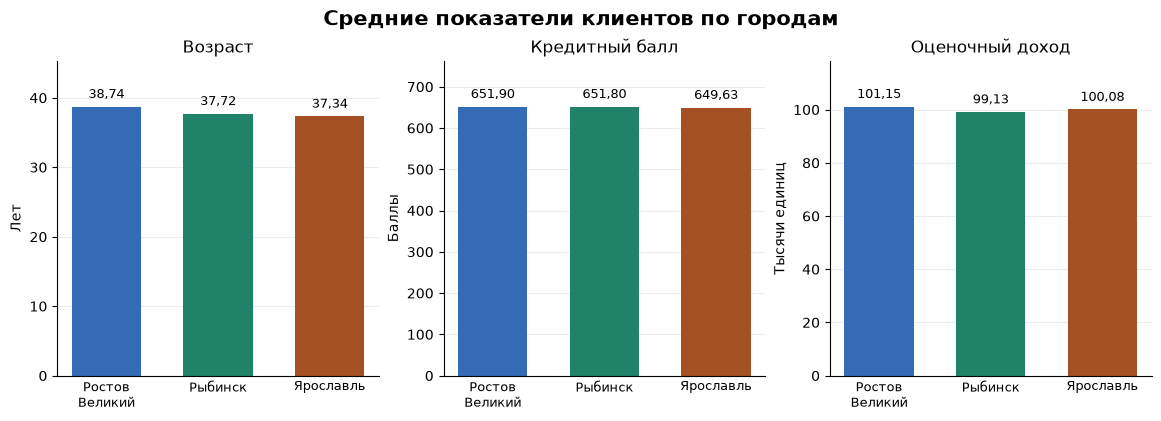

In [5]:
figure, axes = plt.subplots(1, 3, figsize=(11.5, 4.1), layout="constrained")
figure.suptitle("Средние показатели клиентов по городам", fontsize=15, fontweight="bold")

scales = [
    ("Возраст", "Лет", 1),
    ("Кредитный балл", "Баллы", 1),
    ("Оценочный доход", "Тысячи единиц", 1_000),
]
for ax, (metric, unit, divisor) in zip(axes, scales):
    means = stats.loc[metric, "Среднее"] / divisor
    labels = [city.replace(" ", "\n") for city in means.index]
    bars = ax.bar(labels, means, color=["#356AB7", "#208269", "#A65124"], width=0.62)
    values = [f"{value:.2f}".replace(".", ",") for value in means]
    ax.bar_label(bars, labels=values, padding=4, fontsize=9)
    ax.set(title=metric, ylabel=unit, ylim=(0, means.max() * 1.17))
    ax.tick_params(axis="x", length=0, labelsize=9)
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.23)
    ax.spines[["top", "right"]].set_visible(False)

figure.savefig("city_statistics.png", dpi=170, facecolor="white")
plt.show()

### Выводы

1. Из 10 003 записей удалили 3 дубликата и 374 строки с выбросами (3,74% от 10 000 уникальных строк). Из строк с выбросами 359 вышли за верхнюю границу возраста в 62 года и 15 оказались ниже нижней границы кредитного балла в 383. По оценочному доходу выбросов по правилу IQR не обнаружено. В анализ вошли 9 626 клиентов, из них 4 826 в Ярославле, 2 421 в Ростове Великом и 2 379 в Рыбинске.
2. Средний возраст после очистки выше всего в Ростове Великом (38,74 года), ниже всего в Ярославле (37,34 года). Средние кредитные баллы различаются максимум на 2,27 балла — от 649,63 в Ярославле до 651,90 в Ростове Великом.
3. Самый высокий средний оценочный доход у клиентов Ростова Великого (101 149,53), самый низкий — у клиентов Рыбинска (99 133,49). Разница составляет 2 016,04 при стандартном отклонении около 57–58 тыс. внутри каждого города.
4. Правило IQR исключило в том числе клиентов старше 62 лет, чей возраст может быть указан верно. Выводы относятся к выборке после фильтрации.